# LIAR — Embeddings, classificadores e ensembles
Material para estudo e experimentação. Duas classes agrupadas; partições oficiais completas, sem amostragem. Validação inteira para seleção e ajuste do stacking; teste reservado para avaliação. CPS manual.
Classes: 0 = pants-fire/false/barely-true/half-true; 1 = mostly-true/true. CPS via UMAP.

Oracle para pool completo, CPS e HSFN. Sem reamostragem; a classe False é uma convenção experimental que inclui half-true, não uma equivalência semântica.


In [ ]:
%pip -q install numpy pandas requests nltk scipy scikit-learn sentence-transformers matplotlib deslib gensim tensorflow xgboost umap-learn

In [ ]:
import io, re, json, zipfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import requests
import nltk
from nltk.corpus import stopwords
from scipy import sparse
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from gensim.models import Word2Vec, FastText
from sentence_transformers import SentenceTransformer
import matplotlib.pyplot as plt
import joblib
SAVE_MODELS = False  # True apenas se precisar gerar embeddings de novos textos
SEED=42
np.random.seed(SEED)
LIAR_URL='https://www.cs.ucsb.edu/~william/data/liar_dataset.zip'
ROOT=Path('/content') if Path('/content').exists() else Path('.')
OUTPUT_DIR=ROOT/'liar_25_binario_umap_results' / 'embeddings'
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
SPLITS=('train','validation','test')
DATASETS=('liar',)
EMBEDDINGS=('bert','cv','tfidf','w2v','fasttext')
LABEL_MAPS={
 'liar':{'pants-fire':0,'false':0,'barely-true':0,'half-true':0,'mostly-true':1,'true':1}}
CLASS_NAMES={0:'False',1:'True'}
CLASS_GRAY_COLORS={'liar':{0:'#252525',1:'#737373'}}
nltk.download('stopwords',quiet=True)
STOPWORDS=set(stopwords.words('english'))-{'no','not','nor','never'}
NEGATIONS={'no','not','nor','never'}
from IPython.display import display
USE_SAMPLE = False
SAMPLE_SIZE = None


## 1. Dados — partições oficiais completas

train 10240


,count
original_label,
half-true,2114
false,1995
mostly-true,1962
true,1676
barely-true,1654
pants-fire,839


,count
liar,
False,6602
True,3638


validation 1284


,count
original_label,
false,263
mostly-true,251
half-true,248
barely-true,237
true,169
pants-fire,116


,count
liar,
False,864
True,420


test 1267


,count
original_label,
half-true,265
false,249
mostly-true,241
barely-true,212
true,208
pants-fire,92


,count
liar,
False,818
True,449


,False,True
train,6602,3638
validation,864,420
test,818,449
Total,8284,4507


,False,True
train,64.47,35.53
validation,67.29,32.71
test,64.56,35.44
Total,64.76,35.24


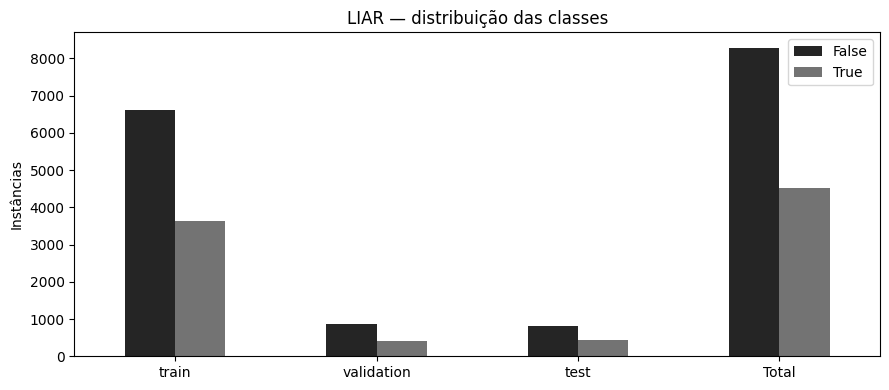

In [ ]:
def load_liar():
    response = requests.get(LIAR_URL, timeout=120)
    response.raise_for_status()
    filenames = {"train": "train.tsv", "validation": "valid.tsv", "test": "test.tsv"}
    splits = {}
    with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
        for split, filename in filenames.items():
            member = next((name for name in archive.namelist() if name.endswith(filename)), None)
            if member is None:
                raise FileNotFoundError(f"Arquivo {filename} ausente no ZIP")
            with archive.open(member) as f:
                df = pd.read_csv(f, sep="\t", header=None, dtype=str)
            df = df.iloc[:, [2, 1]].copy()
            df.columns = ["statement", "original_label"]
            df["statement"] = df["statement"].fillna("").astype(str)
            df["original_label"] = df["original_label"].str.strip().str.lower()
            for name, mapping in LABEL_MAPS.items():
                df[name] = df["original_label"].map(mapping)
                if df[name].isna().any():
                    raise ValueError(f"Rótulos não reconhecidos no split {split}: {name}")
                df[name] = df[name].astype(int)
            splits[split] = df.reset_index(drop=True)
    return splits

labels = load_liar()
for s, df in labels.items():
    print(s, len(df))
    display(df["original_label"].value_counts())
    display(df["liar"].map(CLASS_NAMES).value_counts())

# Distribuição binária por partição, sem reamostragem.
counts = pd.DataFrame({s: df["liar"].value_counts().reindex([0,1],fill_value=0) for s,df in labels.items()}).T
counts.columns=["False","True"]
counts.loc["Total"]=counts.sum()
display(counts)
display(counts.div(counts.sum(axis=1),axis=0).mul(100).round(2))
ax=counts.plot.bar(rot=0,figsize=(9,4),color=["#252525","#737373"])
ax.set(ylabel="Instâncias",title="LIAR — distribuição das classes")
ax.figure.tight_layout(); ax.figure.savefig(OUTPUT_DIR.parent/"distribuicao_classes.jpg",dpi=300); plt.show()

In [ ]:
def clean_text(text):
    """Limpeza do EDA, com preservação explícita das negações."""
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    return " ".join(
        word for word in text.split()
        if (len(word) > 2 or word in NEGATIONS) and word not in STOPWORDS
    )
for df in labels.values():
    df["clean_text"] = df["statement"].map(clean_text)

## 2. Representações textuais
CV, TF-IDF, Word2Vec e FastText ajustados somente no treino; MiniLM pré-treinado usa texto original.

In [ ]:
X = {e: {} for e in EMBEDDINGS}
train_text = labels['train']['clean_text'].tolist()
vectorizers = {
    'cv': CountVectorizer(max_features=20000, token_pattern=r"(?u)\b\w+\b"),
    'tfidf': TfidfVectorizer(max_features=20000, sublinear_tf=True, token_pattern=r"(?u)\b\w+\b")
}
for e, vectorizer in vectorizers.items():
    vectorizer.fit(train_text)
    for s, df in labels.items():
        X[e][s] = vectorizer.transform(df['clean_text'])
# Word2Vec: parâmetros do Notebook 2 original.
w2v = Word2Vec(sentences=[t.split() for t in train_text], vector_size=100,
               window=5, min_count=1, workers=1, sg=1, epochs=10, seed=SEED)
def average_w2v(model, texts):
    result = np.zeros((len(texts), model.vector_size), dtype=np.float32)
    for i, t in enumerate(texts):
        vec = [model.wv[w] for w in t.split() if w in model.wv]
        if vec:
            result[i] = np.mean(vec, axis=0)
    return result
for s, df in labels.items():
    X['w2v'][s] = average_w2v(w2v, df['clean_text'].tolist())
fasttext = FastText(sentences=[t.split() for t in train_text], vector_size=100,
                    window=5, min_count=1, workers=1, sg=1, epochs=10, seed=SEED)
for s, df in labels.items():
    X['fasttext'][s] = average_w2v(fasttext, df['clean_text'].tolist())
bert = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')
for s, df in labels.items():
    X['bert'][s] = bert.encode(df['statement'].tolist(), batch_size=64, show_progress_bar=True, convert_to_numpy=True).astype(np.float32)
    print(s, {e: X[e][s].shape for e in EMBEDDINGS})

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (9 outputs left out)

Batches:   0%|          | 0/21 [00:00<?, ?it/s]

validation {'bert': (1284, 384), 'cv': (1284, 11381), 'tfidf': (1284, 11381), 'w2v': (1284, 100), 'fasttext': (1284, 100)}


Batches:   0%|          | 0/20 [00:00<?, ?it/s]

test {'bert': (1267, 384), 'cv': (1267, 11381), 'tfidf': (1267, 11381), 'w2v': (1267, 100), 'fasttext': (1267, 100)}


In [ ]:

# ============================================================
# SALVAR E BAIXAR REPRESENTAÇÕES TEXTUAIS
# ============================================================

import joblib
import zipfile
from google.colab import files

checkpoint_embeddings = {
    "X": X,
    "labels": labels,
    "EMBEDDINGS": EMBEDDINGS,
    "SEED": SEED
}

# Salvar representações
joblib.dump(
    checkpoint_embeddings,
    "representacoes_liar.joblib",
    compress=3
)

# Criar ZIP
with zipfile.ZipFile(
    "representacoes_liar.zip",
    "w",
    zipfile.ZIP_DEFLATED
) as z:
    z.write("representacoes_liar.joblib")

# Baixar
files.download("representacoes_liar.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

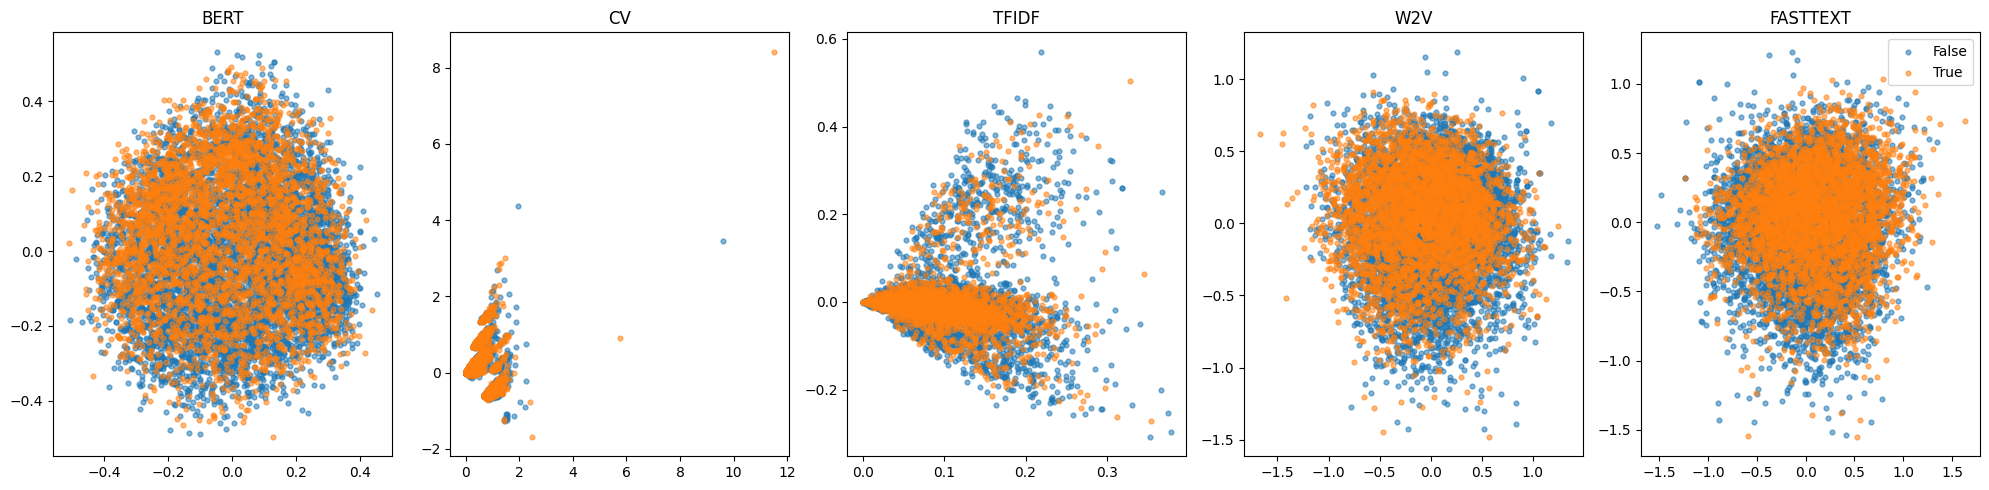

In [ ]:
from sklearn.decomposition import PCA, TruncatedSVD
OUT = ROOT/'liar_25_binario_umap_results'
OUT.mkdir(exist_ok=True)
fig, axes = plt.subplots(1,len(EMBEDDINGS),figsize=(20,5))
for ax,e in zip(axes,EMBEDDINGS):
    mat=X[e]['train']; reducer=TruncatedSVD(n_components=2,random_state=SEED) if sparse.issparse(mat) else PCA(n_components=2,random_state=SEED)
    z=reducer.fit_transform(mat)
    for i,name in CLASS_NAMES.items():
        mask=labels['train']['liar'].to_numpy()==i
        ax.scatter(*z[mask].T,s=12,alpha=.55,label=name)
    ax.set_title(e.upper())
axes[-1].legend(); fig.tight_layout(); fig.savefig(OUT/'embeddings.jpg',dpi=300); plt.show()

## 3. Cinquenta classificadores
Preserva hiperparâmetros do Notebook 3. CNN exploratória Conv1D sobre atributos, não sobre sequência de tokens; CV e TF-IDF passam por SVD ajustado no treino.
Novos modelos: NB multinomial para CV/TF-IDF e gaussiano para embeddings densos; ET é uma árvore ExtraTree individual. RF, XB, RL e MLP usam configurações fixas explícitas, sem busca de hiperparâmetros. MLP usa escala ajustada apenas no treino.

In [ ]:

# ============================================================
# CLASSIFICADORES DE BASE — 25 MODELOS
# ============================================================

import numpy as np

from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import TruncatedSVD
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score, accuracy_score

from tensorflow import keras
from tensorflow.keras import layers

ALGORITHMS = ('SVM', 'KNN', 'CNN', 'NB', 'RF')

MODEL_NAMES = [
    f'{e.upper()}-{a}'
    for e in EMBEDDINGS
    for a in ALGORITHMS
]

print("Total de classificadores:", len(MODEL_NAMES))

# ============================================================
# CONFIGURAÇÕES DA CNN
# ============================================================

# CNN exploratória 1D sobre o eixo de atributos.
# Para CV/TF-IDF, utilizamos SVD ajustado somente no treino.
# Não equivale a uma TextCNN sobre sequências de tokens.

CNN_EPOCHS = 8
CNN_BATCH = 128
CNN_DIM = 128

CNN_INPUT = {}

for e in EMBEDDINGS:

    if e in ('cv', 'tfidf'):

        maxdim = min(
            CNN_DIM,
            X[e]['train'].shape[1] - 1,
            X[e]['train'].shape[0] - 1
        )

        reducer = TruncatedSVD(
            n_components=maxdim,
            random_state=SEED
        )

        CNN_INPUT[e] = {
            'train': reducer.fit_transform(
                X[e]['train']
            ).astype('float32')
        }

        for s in ('validation', 'test'):
            CNN_INPUT[e][s] = reducer.transform(
                X[e][s]
            ).astype('float32')

    else:

        CNN_INPUT[e] = {
            s: np.asarray(X[e][s], dtype='float32')
            for s in SPLITS
        }

    # Normalização ajustada exclusivamente no treino
    scaler = StandardScaler()

    CNN_INPUT[e]['train'] = scaler.fit_transform(
        CNN_INPUT[e]['train']
    ).astype('float32')

    for s in ('validation', 'test'):
        CNN_INPUT[e][s] = scaler.transform(
            CNN_INPUT[e][s]
        ).astype('float32')


# ============================================================
# CLASSIFICADORES TRADICIONAIS
# ============================================================

def make_model(a, e):

    if a == 'SVM':
        return SVC(
            kernel='linear',
            C=1.0,
            probability=True,
            random_state=SEED
        )

    if a == 'KNN':
        return KNeighborsClassifier(
            n_neighbors=7,
            metric='cosine',
            algorithm='brute',
            n_jobs=-1
        )

    if a == 'NB':
        if e in ('cv', 'tfidf'):
            return MultinomialNB(alpha=1.0)
        return GaussianNB()

    if a == 'RF':
        return RandomForestClassifier(
            n_estimators=100,
            random_state=SEED,
            n_jobs=-1
        )

    raise ValueError(a)


# ============================================================
# ARQUITETURA CNN
# ============================================================

def build_cnn(n_features, n_classes):

    keras.utils.set_random_seed(SEED)

    inp = keras.Input(shape=(n_features, 1))

    h = layers.Conv1D(
        32, 5, padding='same', activation='relu'
    )(inp)

    h = layers.MaxPooling1D(2)(h)

    h = layers.Conv1D(
        64, 3, padding='same', activation='relu'
    )(h)

    h = layers.GlobalMaxPooling1D()(h)
    h = layers.Dropout(0.3)(h)

    out = layers.Dense(
        n_classes,
        activation='softmax'
    )(h)

    net = keras.Model(inp, out)

    net.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy'
    )

    return net


# ============================================================
# ENTRADA DOS CLASSIFICADORES
# ============================================================

def get_input(e, a, s):

    if a == 'CNN':
        return CNN_INPUT[e][s][..., None]

    return X[e][s]


# ============================================================
# TREINAMENTO E PREDIÇÃO
# ============================================================

def train_base(dataset, e, a):

    y = labels['train'][dataset].to_numpy(dtype=int)

    classes = np.sort(np.unique(y))
    expected = np.arange(len(classes))

    if not np.array_equal(classes, expected):
        raise ValueError(
            f'Classes inesperadas em {dataset}: {classes}'
        )

    for split in ('validation', 'test'):

        observed = np.unique(
            labels[split][dataset].to_numpy(dtype=int)
        )

        if not np.isin(observed, classes).all():
            raise ValueError(
                f'Classes inesperadas em {split}/{dataset}: '
                f'{observed}'
            )

    # CNN
    if a == 'CNN':

        keras.backend.clear_session()

        net = build_cnn(
            CNN_INPUT[e]['train'].shape[1],
            len(classes)
        )

        net.fit(
            get_input(e, a, 'train'),
            y,
            epochs=CNN_EPOCHS,
            batch_size=CNN_BATCH,
            verbose=0
        )

        return {
            s: net.predict(
                get_input(e, a, s),
                verbose=0
            )
            for s in ('validation', 'test')
        }

    # SVM, KNN, NB e RF
    clf = make_model(a, e)

    clf.fit(get_input(e, a, 'train'), y)

    if not np.array_equal(clf.classes_, classes):
        raise ValueError(
            f'Ordem das classes inesperada: {clf.classes_}'
        )

    return {
        s: clf.predict_proba(get_input(e, a, s))
        for s in ('validation', 'test')
    }

Total de classificadores: 25


In [ ]:
base_outputs={}
records=[]
for d in DATASETS:
    base_outputs[d]={'pred':{},'proba':{}}
    for s in ('validation','test'):
        base_outputs[d]['pred'][s]={};base_outputs[d]['proba'][s]={}
    for e in EMBEDDINGS:
        for a in ALGORITHMS:
            name=f'{e.upper()}-{a}'
            print('Treinando',d,name,flush=True)
            probs=train_base(d,e,a)
            for s,p in probs.items():
                p=np.asarray(p,dtype=np.float32)
                n_classes=len(np.unique(labels['train'][d].to_numpy(dtype=int)))
                if p.ndim != 2 or p.shape != (len(labels[s]),n_classes):
                    raise ValueError(f'Probabilidades inválidas para {d}/{name}/{s}: {p.shape}')
                pred=p.argmax(axis=1)
                base_outputs[d]['proba'][s][name]=p
                base_outputs[d]['pred'][s][name]=pred
                y=labels[s][d].to_numpy(dtype=int)
                records.append(dict(dataset=d,model=name,algorithm=a,embedding=e.upper(),split=s,
                                    f1_macro=f1_score(y,pred,average='macro',zero_division=0),
                                    accuracy=accuracy_score(y,pred)))
base_scores=pd.DataFrame(records)

Treinando liar BERT-SVM
Treinando liar BERT-KNN
Treinando liar BERT-CNN
Treinando liar BERT-NB
Treinando liar BERT-RF
Treinando liar CV-SVM
Treinando liar CV-KNN
Treinando liar CV-CNN
Treinando liar CV-NB
Treinando liar CV-RF
Treinando liar TFIDF-SVM
Treinando liar TFIDF-KNN
Treinando liar TFIDF-CNN
Treinando liar TFIDF-NB
Treinando liar TFIDF-RF
Treinando liar W2V-SVM
Treinando liar W2V-KNN
Treinando liar W2V-CNN
Treinando liar W2V-NB
Treinando liar W2V-RF
Treinando liar FASTTEXT-SVM
Treinando liar FASTTEXT-KNN
Treinando liar FASTTEXT-CNN
Treinando liar FASTTEXT-NB
Treinando liar FASTTEXT-RF


NameError: name 'OUT' is not defined

In [ ]:
base_scores.to_csv(OUT/'metricas_modelos_base.csv',index=False)
print('Resultados:',OUT/'metricas_modelos_base.csv')

Resultados: /content/liar_25_binario_umap_results/metricas_modelos_base.csv


In [ ]:
# Checkpoint para retomar HSFN/CPS sem treinar novamente.
checkpoint = dict(X=X, labels=labels, base_outputs=base_outputs, base_scores=base_scores,
                  MODEL_NAMES=MODEL_NAMES, EMBEDDINGS=EMBEDDINGS, ALGORITHMS=ALGORITHMS,
                  DATASETS=DATASETS, SPLITS=SPLITS, SEED=SEED)
joblib.dump(checkpoint, ROOT/'liar_25_binario_umap_checkpoint.joblib', compress=3)
print('Checkpoint salvo. Copie para armazenamento persistente se estiver no Colab.')

Checkpoint salvo. Copie para armazenamento persistente se estiver no Colab.


Para retomar em outra sessão, execute as células de instalação e configuração e carregue o checkpoint com `globals().update(joblib.load(ROOT / "liar_25_binario_umap_checkpoint.joblib"))`. Depois execute a seção 4 em diante. Carregue apenas arquivos joblib confiáveis.

,dataset,model,algorithm,embedding,split,f1_macro,accuracy
0,liar,BERT-SVM,SVM,BERT,validation,0.402235,0.672897
1,liar,BERT-SVM,SVM,BERT,test,0.392326,0.645620
2,liar,BERT-KNN,KNN,BERT,validation,0.585905,0.663551
3,liar,BERT-KNN,KNN,BERT,test,0.571539,0.636938
4,liar,BERT-CNN,CNN,BERT,validation,0.402235,0.672897
5,liar,BERT-CNN,CNN,BERT,test,0.392326,0.645620
6,liar,BERT-NB,NB,BERT,validation,0.588940,0.620717
7,liar,BERT-NB,NB,BERT,test,0.594744,0.616417
8,liar,BERT-RF,RF,BERT,validation,0.518242,0.689252
9,liar,BERT-RF,RF,BERT,test,0.485135,0.662194


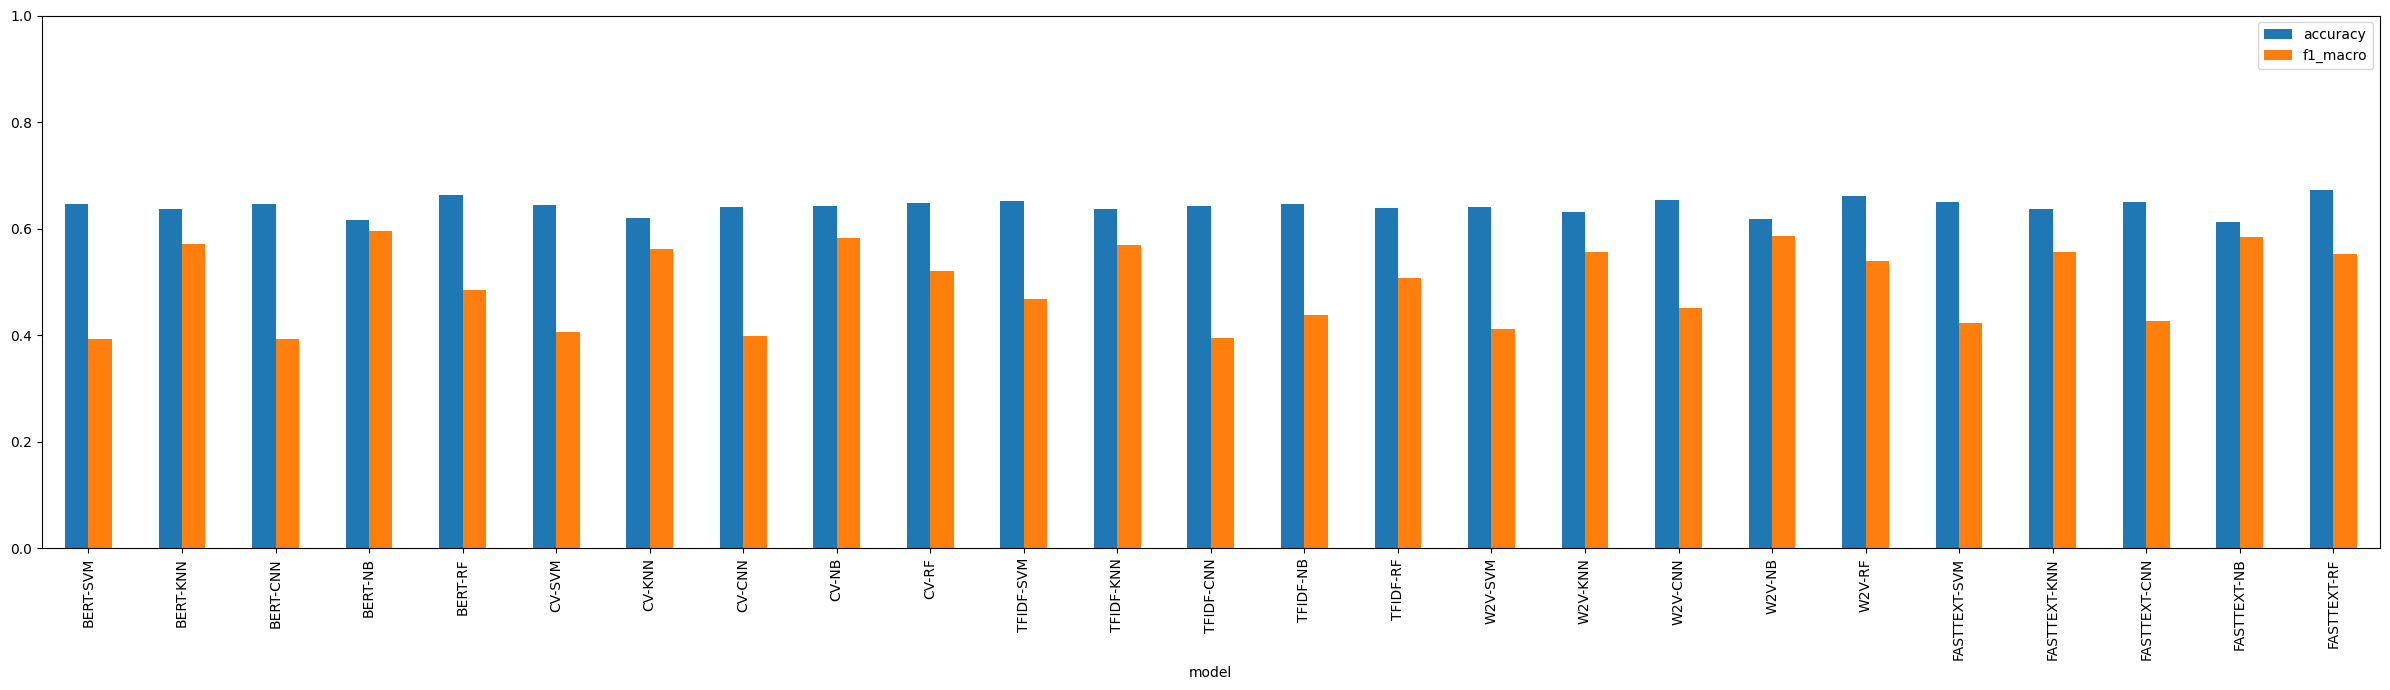

In [ ]:
display(base_scores)
ax=base_scores.query('split == "test"').set_index('model')[['accuracy','f1_macro']].plot.bar(figsize=(24,7),ylim=(0,1))
ax.figure.tight_layout(); ax.figure.savefig(OUT/'monoliticos.jpg',dpi=300); plt.show()

## 4. HSFN e CPS
Double Fault via DESlib; HSFN com linkage average sobre triangular superior, CPS com UMAP sobre inverso de Double Fault, inspirado em Cruz et al. (2022), seções 3.3–3.4. Parâmetros UMAP escolhidos para este experimento; DF zero fora da diagonal regularizado com 1/N. https://github.com/Menelau/Hate-Speech-MCS

In [ ]:

# ============================================================
# CONFIGURAÇÕES — HSFN, CPS E STACKING
# ============================================================

from pathlib import Path
from zipfile import ZipFile
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.lines import Line2D
from scipy.spatial.distance import squareform
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from umap import UMAP

from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import f1_score, accuracy_score
from IPython.display import display

SEED = 42

# Diretório de resultados
OUT = ROOT / 'liar_25_binario_umap_results' / 'ensembles'
OUT.mkdir(parents=True, exist_ok=True)

ZIP_PATH = ROOT / 'predicoes_modelos_base_25.zip'

DATASETS = ('liar',)

# Representações textuais
EMBEDDINGS = ('bert', 'cv', 'tfidf', 'w2v', 'fasttext')

# Algoritmos de classificação
ALGORITHMS = ('SVM', 'KNN', 'CNN', 'NB', 'RF')

# Pool de classificadores
MODEL_NAMES = [
    f'{e.upper()}-{a}'
    for e in EMBEDDINGS
    for a in ALGORITHMS
]

# Cores dos algoritmos
COLORS = {
    'SVM': '#F28E2B',
    'KNN': '#B07AA1',
    'CNN': '#E15759',
    'NB':  '#76B7B2',
    'RF':  '#59A14F'
}

# Marcadores dos algoritmos
MARKERS = {
    'SVM': '^',
    'KNN': 'D',
    'CNN': 'P',
    'NB':  'v',
    'RF':  's'
}

DS_TITLES = {'liar': 'LIAR (2 classes)'}


def algorithm(name):
    return name.rsplit('-', 1)[-1]


def embedding(name):
    return name.rsplit('-', 1)[0].lower()


print('Representações:', len(EMBEDDINGS))
print('Algoritmos:', len(ALGORITHMS))
print('Total de classificadores:', len(MODEL_NAMES))
print('Saída:', OUT)


Representações: 5
Algoritmos: 5
Total de classificadores: 25
Saída: /content/liar_25_binario_umap_results/ensembles


In [ ]:
ds='liar'
data=base_outputs[ds]
assert all(p.shape[1] == 2 for split in ('validation','test') for p in data['proba'][split].values()), 'Checkpoint incompatível: retreine para duas classes.'
data['y']={s:labels[s][ds].to_numpy(dtype=int) for s in ('validation','test')}
val_metrics={ds:{m:f1_score(data['y']['validation'],data['pred']['validation'][m],average='macro',zero_division=0) for m in MODEL_NAMES}}

In [ ]:
DOUBLE_FAULT = {}
DISTANCES = {}
LINKAGES = {}
REPRESENTATIVES = {}
CLUSTERS = {}
cluster_rows, representative_rows = [], []

for ds in DATASETS:
    y = base_outputs[ds]['y']['validation']
    err = np.column_stack([
        base_outputs[ds]['pred']['validation'][m] != y
        for m in MODEL_NAMES
    ]).astype(float)
    from deslib.util.diversity import double_fault
    df = np.array([[double_fault(y, base_outputs[ds]['pred']['validation'][a], base_outputs[ds]['pred']['validation'][b]) for b in MODEL_NAMES] for a in MODEL_NAMES])
    dist = np.mean(err[:,:,None] != err[:,None,:], axis=0)
    np.fill_diagonal(dist, 0.0)
    DOUBLE_FAULT[ds], DISTANCES[ds] = df, dist
    Z = linkage(np.triu(df), method='average')
    LINKAGES[ds] = Z
    REPRESENTATIVES[ds], CLUSTERS[ds] = {}, {}
    for k in range(1,len(MODEL_NAMES)+1):
        labels_k = cut_tree(Z, n_clusters=k).ravel() + 1
        groups = {}
        for i, cid in enumerate(labels_k):
            groups.setdefault(int(cid),[]).append(MODEL_NAMES[i])
        reps = [sorted(members,key=lambda m:(-val_metrics[ds][m],m))[0]
                for _,members in sorted(groups.items())]
        # cut_tree retorna exatamente k clusters, inclusive com distâncias empatadas.
        CLUSTERS[ds][k] = groups
        REPRESENTATIVES[ds][k] = reps
        for cid,members in sorted(groups.items()):
            cluster_rows.append({'dataset':ds,'k_requested':k,'k_actual':len(groups),'cluster':cid,'models':' | '.join(members)})
        representative_rows.append({'dataset':ds,'k_requested':k,'k_actual':len(groups),'models':' | '.join(reps)})
    print(ds, 'double-fault:',df.shape, 'linkage:',Z.shape)

clusters_df = pd.DataFrame(cluster_rows)
representatives_df = pd.DataFrame(representative_rows)

liar double-fault: (25, 25) linkage: (24, 4)


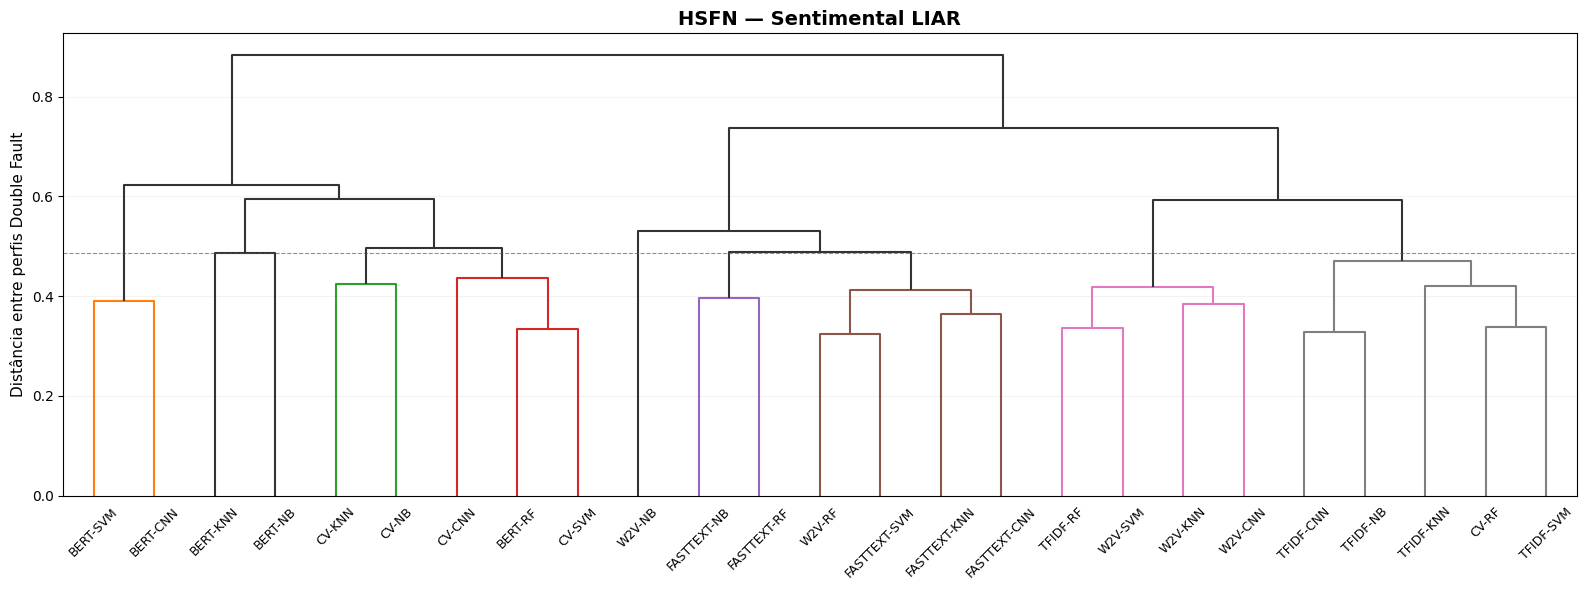

In [ ]:

# ============================================================
# DENDROGRAMA HSFN
# ============================================================

fig, ax = plt.subplots(figsize=(16, 6))

for ds in DATASETS:

    Z = LINKAGES[ds]

    # Corte visual para colorir os ramos
    heights = np.unique(Z[:, 2])

    threshold = (
        float(np.quantile(heights, 0.65))
        if len(heights) > 1
        else float(heights[0]) * 0.99
    )

    dendrogram(
        Z,
        labels=MODEL_NAMES,
        leaf_rotation=45,
        leaf_font_size=9,
        color_threshold=threshold,
        above_threshold_color='#333333',
        ax=ax
    )

    ax.axhline(
        threshold,
        color='#555555',
        ls='--',
        lw=0.8,
        alpha=0.65
    )

    ax.set_title(
        'HSFN — Sentimental LIAR',
        fontsize=14,
        fontweight='bold'
    )

    ax.set_ylabel(
        'Distância entre perfis Double Fault',
        fontsize=11
    )

    ax.grid(axis='y', alpha=0.15)

fig.tight_layout()

fig.savefig(
    OUT / 'hsfn_dendrogramas_coloridos.jpg',
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()
plt.close(fig)


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1865: UserWarning: using precomputed metric; inverse_transform will be unavailable
  warn("using precomputed metric; inverse_transform will be unavailable")


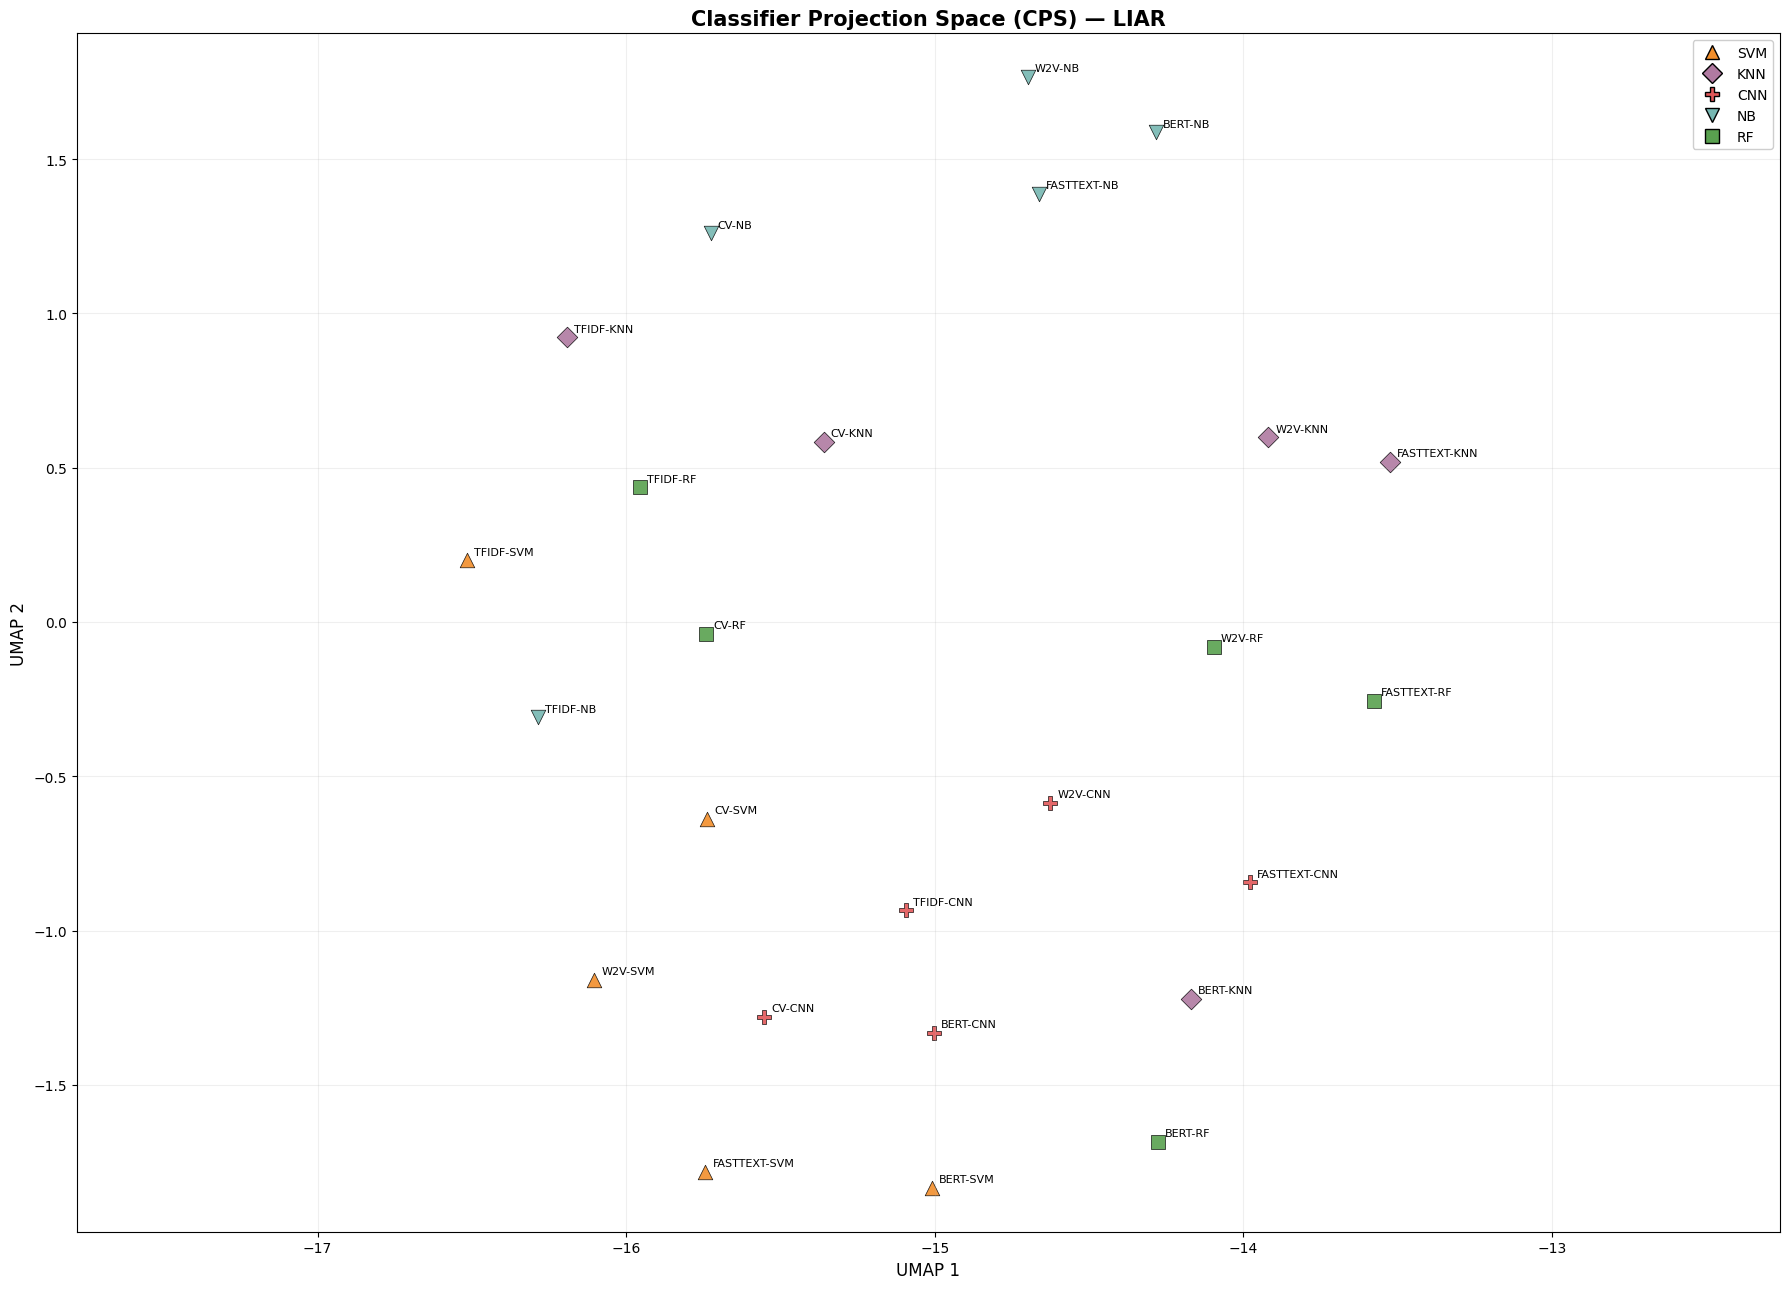


LIAR — F1-macro na validação (para orientar a seleção manual)


,model,accuracy_validation,f1_validation
0,CV-KNN,0.669003,0.589524
1,BERT-NB,0.620717,0.588940
2,W2V-NB,0.625389,0.588803
3,BERT-KNN,0.663551,0.585905
4,FASTTEXT-NB,0.619938,0.583454
5,CV-NB,0.647975,0.571650
6,W2V-KNN,0.653427,0.567992
7,FASTTEXT-KNN,0.652648,0.567395
8,TFIDF-KNN,0.648754,0.562921
9,W2V-RF,0.689252,0.559430


In [ ]:

# ============================================================
# CPS — APENAS LIAR
# ============================================================

ds = "liar"

# UMAP sobre dissimilaridade precomputada (inverso do Double Fault).
# Adaptação da seção 3.4 de Cruz et al. (2022); parâmetros explícitos deste experimento.
# Para DF=0 fora da diagonal, usar um piso de 1/N evita distância zero indevida.
df = DOUBLE_FAULT[ds]
D = 1.0 / np.maximum(df, 1.0 / len(data['y']['validation']))
np.fill_diagonal(D, 0.0)
assert np.allclose(D, D.T) and np.isfinite(D).all()
CPS_DISTANCES = {ds: D}
reducer_umap = UMAP(n_components=2, metric='precomputed',
                    n_neighbors=15, min_dist=0.1, random_state=SEED,
                    init='random', n_jobs=1)
coords = reducer_umap.fit_transform(D)

# Armazenar coordenadas para uso posterior
CPS_COORDS = globals().get("CPS_COORDS", {})
CPS_COORDS[ds] = coords

# Criar figura única
fig, ax = plt.subplots(figsize=(18, 13))

for i, m in enumerate(MODEL_NAMES):
    a = algorithm(m)

    ax.scatter(
        coords[i, 0],
        coords[i, 1],
        color=COLORS[a],
        marker=MARKERS[a],
        s=110,
        edgecolors="black",
        linewidths=0.5,
        alpha=0.9
    )

    ax.annotate(
        m,
        coords[i],
        xytext=(5, 4),
        textcoords="offset points",
        fontsize=8
    )

# Configurações do gráfico
ax.set_title(
    "Classifier Projection Space (CPS) — LIAR",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("UMAP 1", fontsize=12)
ax.set_ylabel("UMAP 2", fontsize=12)
ax.grid(alpha=0.2)
ax.set_aspect("equal", adjustable="datalim")

# Legenda por algoritmo
handles = [
    Line2D(
        [0], [0],
        marker=MARKERS[a],
        color="w",
        markerfacecolor=COLORS[a],
        markeredgecolor="black",
        markersize=10,
        label=a
    )
    for a in ALGORITHMS
]

ax.legend(
    handles=handles,
    loc="best",
    ncol=1,
    frameon=True,
    facecolor="white",
    edgecolor="#CCCCCC",
    framealpha=0.95,
    fontsize=10
)

fig.tight_layout()
#fig.tight_layout(rect=(0, 0.07, 1, 1))

# Salvar em JPG com alta resolução
fig.savefig(
    OUT / "cps_liar_cores_marcadores.jpg",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# F1-MACRO — VALIDAÇÃO DO LIAR
# ============================================================

print(
    "\nLIAR — F1-macro na validação "
    "(para orientar a seleção manual)"
)

df_liar = pd.DataFrame({
    "model": MODEL_NAMES,
    "accuracy_validation": [accuracy_score(base_outputs[ds]["y"]["validation"], base_outputs[ds]["pred"]["validation"][m]) for m in MODEL_NAMES],
    "f1_validation": [
        val_metrics[ds][m]
        for m in MODEL_NAMES
    ]
})

display(
    df_liar.sort_values(
        "f1_validation",
        ascending=False
    ).reset_index(drop=True)
)


In [ ]:

# ============================================================
# CPS — SELEÇÃO MANUAL DO CPS (APENAS LIAR)
# ============================================================

ds = "liar"

# Preencha manualmente ou deixe None para usar input()
CPS_SELECTIONS = {
    "liar": None
}

def validate_manual_choice(ds, selected):
    if isinstance(selected, str):
        selected = [
            s.strip().upper()
            for s in selected.split(",")
            if s.strip()
        ]

    if selected is None or len(selected) != 6 or len(set(selected)) != 6:
        raise ValueError(
            f"{ds}: selecione exatamente cinco modelos distintos."
        )

    unknown = set(selected) - set(MODEL_NAMES)

    if unknown:
        raise ValueError(
            f"{ds}: nomes inválidos: {sorted(unknown)}"
        )

    return selected


print(f"\nCPS — {DS_TITLES[ds]}")
print("Observe o CPS acima e escolha CINCO modelos distintos.")
print("Modelos válidos:", ", ".join(MODEL_NAMES))

if CPS_SELECTIONS[ds] is None:
    chosen = input(
        "Informe os modelos para LIAR, separados por vírgula: "
    )
else:
    chosen = CPS_SELECTIONS[ds]

CPS_SELECTIONS[ds] = validate_manual_choice(ds, chosen)

print("\nEscolha registrada:")
for modelo in CPS_SELECTIONS[ds]:
    print(" -", modelo)

# Salvar seleção manual
(OUT / "selecao_manual_cps_liar.json").write_text(
    json.dumps(
        CPS_SELECTIONS,
        indent=2,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

print("\nSeleção salva com sucesso.")



CPS — LIAR (2 classes)
Observe o CPS acima e escolha CINCO modelos distintos.
Modelos válidos: BERT-SVM, BERT-KNN, BERT-CNN, BERT-NB, BERT-RF, CV-SVM, CV-KNN, CV-CNN, CV-NB, CV-RF, TFIDF-SVM, TFIDF-KNN, TFIDF-CNN, TFIDF-NB, TFIDF-RF, W2V-SVM, W2V-KNN, W2V-CNN, W2V-NB, W2V-RF, FASTTEXT-SVM, FASTTEXT-KNN, FASTTEXT-CNN, FASTTEXT-NB, FASTTEXT-RF
Informe os modelos para LIAR, separados por vírgula:  W2V-NB,CV-KNN,TFIDF-SVM,BERT-CNN,FASTTEXT-RF,W2V-KNN

Escolha registrada:
 - W2V-NB
 - CV-KNN
 - TFIDF-SVM
 - BERT-CNN
 - FASTTEXT-RF
 - W2V-KNN

Seleção salva com sucesso.


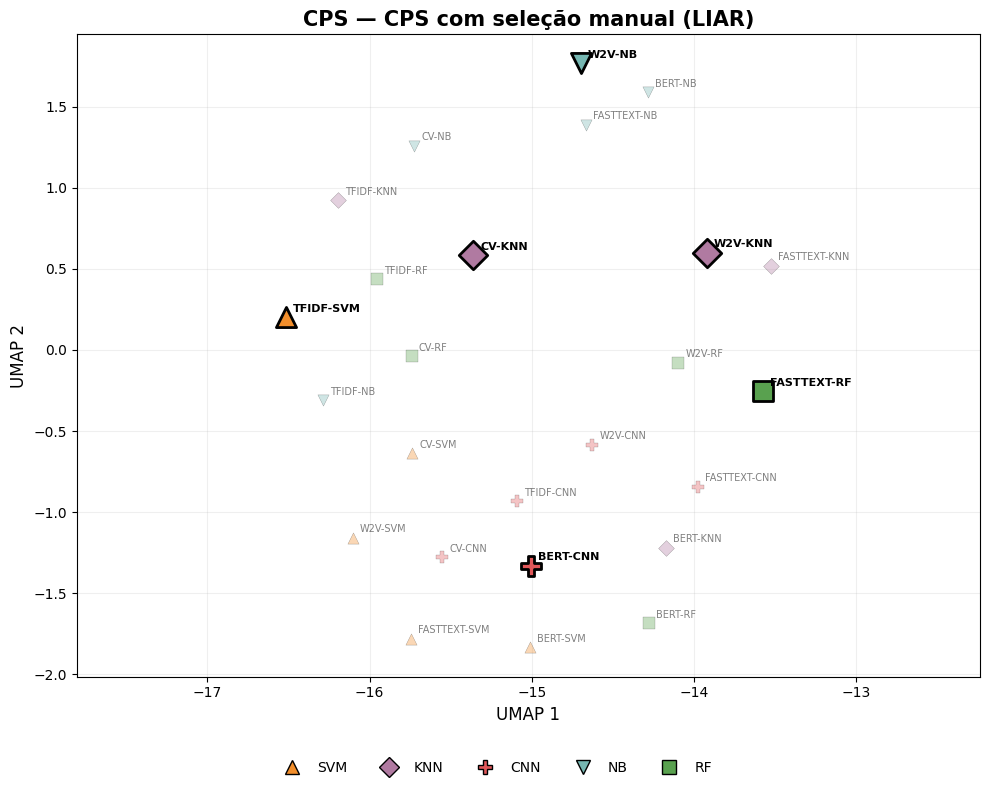


Classificadores selecionados — CPS (LIAR):
 - W2V-NB
 - CV-KNN
 - TFIDF-SVM
 - BERT-CNN
 - FASTTEXT-RF
 - W2V-KNN


In [ ]:

# ============================================================
# CPS — CPS COM SELEÇÃO MANUAL DESTACADA (LIAR)
# ============================================================

ds = "liar"

coords = CPS_COORDS[ds]
selecionados = CPS_SELECTIONS[ds]

fig, ax = plt.subplots(figsize=(10, 8))

for i, m in enumerate(MODEL_NAMES):
    a = algorithm(m)
    chosen = m in selecionados

    ax.scatter(
        coords[i, 0],
        coords[i, 1],
        color=COLORS[a],
        marker=MARKERS[a],
        s=210 if chosen else 65,
        edgecolors="black",
        linewidths=2 if chosen else 0.3,
        alpha=1 if chosen else 0.35,
        zorder=3 if chosen else 2
    )

    ax.annotate(
        m,
        coords[i],
        xytext=(5, 4),
        textcoords="offset points",
        fontsize=8 if chosen else 7,
        fontweight="bold" if chosen else "normal",
        alpha=1 if chosen else 0.5
    )

ax.set_title(
    "CPS — CPS com seleção manual (LIAR)",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("UMAP 1", fontsize=12)
ax.set_ylabel("UMAP 2", fontsize=12)
ax.grid(alpha=0.2)
ax.set_aspect("equal", adjustable="datalim")

# Legenda por algoritmo
handles = [
    Line2D(
        [0], [0],
        marker=MARKERS[a],
        color="w",
        markerfacecolor=COLORS[a],
        markeredgecolor="black",
        markersize=10,
        label=a
    )
    for a in ALGORITHMS
]

fig.legend(
    handles=handles,
    loc="lower center",
    ncol=len(ALGORITHMS),
    bbox_to_anchor=(0.5, 0.01),
    frameon=False
)

fig.tight_layout(rect=(0, 0.07, 1, 1))

# Salvar gráfico
fig.savefig(
    OUT / "cps_liar_selecao_manual_destacada.jpg",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nClassificadores selecionados — CPS (LIAR):")
for m in selecionados:
    print(" -", m)


In [ ]:
#ds = 'liar'
#GROUPS = {ds: {'Todos': MODEL_NAMES.copy()}}
#for k, reps in sorted(REPRESENTATIVES[ds].items()):
#    GROUPS[ds][f'HSFN k={k}'] = reps
#GROUPS[ds]['CPS'] = CPS_SELECTIONS[ds]
#assert len(GROUPS[ds]['CPS']) == 5
#print('Candidatos:', len(GROUPS[ds]), '| LIAR')

## 5. Stacking e avaliação
A regressão logística atua como classificador base (RL) e, separadamente, como metaclassificador. O melhor k e melhor monolítico são escolhidos na validação inteira; métricas de validação do stacking são de ajuste, não independentes. Curvas de teste são descritivas.

In [ ]:
# ================================================================
# LIAR BINÁRIO — HSFN revisado + stacking GaussianNB
# Substitua as células antigas de definição de GROUPS e stacking
# por ESTA célula, executando-a após a seleção manual do CPS.
# Requer: base_outputs, MODEL_NAMES, CPS_SELECTIONS, OUT, val_metrics
# ================================================================
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import linkage, cut_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import f1_score, accuracy_score
from deslib.util.diversity import double_fault
from IPython.display import display

ds = 'liar'
data = base_outputs[ds]
y_val = np.asarray(data['y']['validation'], dtype=int)
y_test = np.asarray(data['y']['test'], dtype=int)
n_models = len(MODEL_NAMES)
assert n_models == 25, f'Esperados 25 classificadores; recebidos {n_models}'
assert set(np.unique(y_val)).issubset({0, 1})
assert len(CPS_SELECTIONS[ds]) == 6

# 1. Matriz de Double Fault na validação (orientação igual à referência).
pred_val = np.column_stack([
    np.asarray(data['pred']['validation'][m], dtype=int)
    for m in MODEL_NAMES
])
D = np.zeros((n_models, n_models), dtype=float)
for i in range(n_models):
    for j in range(i + 1, n_models):
        D[i, j] = double_fault(y_val, pred_val[:, i], pred_val[:, j])
        D[j, i] = D[i, j]

# 2. Linkage da referência: linhas da triangular como perfis de atributos.
# NÃO substituir por squareform(D): isso seria outro agrupamento.
D_prime = np.triu(D)
Z = linkage(D_prime, method='average', metric='euclidean')
DOUBLE_FAULT[ds] = D
LINKAGES[ds] = Z

# 3. HSFN: cada grupo recebe o classificador com maior F1 individual.
# cut_tree garante exatamente k grupos, mesmo com empates nas alturas.
# Na referência antiga, fcluster usa cortes por distância: os conjuntos
# podem diferir em k quando há empates.
REPRESENTATIVES[ds] = {}
CLUSTERS[ds] = {}
cluster_rows = []
representative_rows = []

for k in range(1, n_models + 1):
    cluster_ids = cut_tree(Z, n_clusters=k).ravel()
    grupos = {}
    for idx, cid in enumerate(cluster_ids):
        grupos.setdefault(int(cid), []).append(MODEL_NAMES[idx])
    selecionados = [
        max(grupo, key=lambda m: (val_metrics[ds][m], -MODEL_NAMES.index(m)))
        for _, grupo in sorted(grupos.items())
    ]
    assert len(grupos) == len(selecionados) == k
    CLUSTERS[ds][k] = grupos
    REPRESENTATIVES[ds][k] = selecionados
    for cid, membros in sorted(grupos.items()):
        cluster_rows.append(dict(dataset=ds, k_requested=k,
                                 k_actual=k, cluster=cid,
                                 models=' | '.join(membros)))
    representative_rows.append(dict(dataset=ds, k_requested=k,
                                    k_actual=k, models=' | '.join(selecionados)))

clusters_df = pd.DataFrame(cluster_rows)
representatives_df = pd.DataFrame(representative_rows)

# 4. Conjuntos para avaliação justa com o MESMO metaclassificador.
GROUPS = {ds: {'Todos': MODEL_NAMES.copy()}}
for k in range(1, n_models + 1):
    GROUPS[ds][f'HSFN k={k}'] = REPRESENTATIVES[ds][k]
GROUPS[ds]['CPS'] = list(CPS_SELECTIONS[ds])

# 5. Uma probabilidade por classificador: P(classe=0), como o primeiro
# elemento de cada par no filtro ::2 da referência original.
# (Para LIAR binário, P(classe=1) = 1 - P(classe=0).)
def meta_matrix(split, models):
    colunas = []
    for m in models:
        p = np.asarray(data['proba'][split][m], dtype=float)
        assert p.ndim == 2 and p.shape[1] == 2, (split, m, p.shape)
        assert len(p) == len(data['y'][split])
        colunas.append(p[:, 0])
    X_meta = np.column_stack(colunas)
    assert np.isfinite(X_meta).all()
    return X_meta

# 6. Stacking GaussianNB na validação; selecionar k por F1-macro.
stacked = {}
selection_rows = []
for group, models in GROUPS[ds].items():
    X_val_meta = meta_matrix('validation', models)
    clf = GaussianNB()
    clf.fit(X_val_meta, y_val)
    stacked[group] = clf
    pred = clf.predict(X_val_meta)
    selection_rows.append(dict(
        group=group, n_models=len(models),
        f1_validation=f1_score(y_val, pred, average='macro', zero_division=0),
        accuracy_validation=accuracy_score(y_val, pred)
    ))

selection_results = pd.DataFrame(selection_rows)
ks = selection_results[
    selection_results['group'].str.startswith('HSFN k=')
].copy()
ks['k'] = ks['group'].str.extract(r'k=(\d+)').astype(int)
# Desempate: preferir o MENOR k, para reduzir o pool.
ks = ks.sort_values(['f1_validation', 'k'], ascending=[False, True])
BEST_D = str(ks.iloc[0]['group'])
K_HSFN_PRINCIPAL = int(ks.iloc[0]['k'])
best = sorted(MODEL_NAMES, key=lambda m: (-val_metrics[ds][m], m))[0]
selected = ['CPS', BEST_D, 'Todos']
print('HSFN escolhido:', BEST_D)
print('Representantes:', GROUPS[ds][BEST_D])
print('Melhor monolítico:', best)

# 7. Teste final dos ensembles: não selecionar k pelo teste.
rows, all_rows = [], []
for split in ('test',):
    y = np.asarray(data['y'][split], dtype=int)
    preds, probas = {}, {}
    for group, clf in stacked.items():
        X_meta = meta_matrix(split, GROUPS[ds][group])
        pred = clf.predict(X_meta)
        all_rows.append(dict(
            split=split, group=group,
            accuracy=accuracy_score(y, pred),
            f1_macro=f1_score(y, pred, average='macro', zero_division=0)
        ))
        if group in selected:
            name = 'HSFN' if group == BEST_D else group
            preds[name] = pred
            probas[name] = clf.predict_proba(X_meta)

    mono = f'Melhor monolítico | {best}'
    preds[mono] = np.asarray(data['pred'][split][best])
    probas[mono] = np.asarray(data['proba'][split][best])
    for name, pred in preds.items():
        rows.append(dict(
            split=split, group=name,
            accuracy=accuracy_score(y, pred),
            f1_macro=f1_score(y, pred, average='macro', zero_division=0)
        ))
    np.savez_compressed(OUT / f'{split}_predicoes.npz', **preds)
    np.savez_compressed(OUT / f'{split}_probabilidades.npz', **probas)
    np.save(OUT / f'{split}_y.npy', y)

results = pd.DataFrame(rows)
curves = pd.DataFrame(all_rows)
print('\nResultados no teste (GaussianNB):')
display(results.sort_values('f1_macro', ascending=False))
print('\nMelhores valores de k na validação (ajuste, não validação independente):')
display(ks[['k', 'f1_validation', 'accuracy_validation']].head(10))

HSFN escolhido: HSFN k=16
Representantes: ['BERT-SVM', 'BERT-KNN', 'BERT-CNN', 'BERT-NB', 'BERT-RF', 'CV-KNN', 'CV-CNN', 'CV-NB', 'TFIDF-KNN', 'TFIDF-CNN', 'TFIDF-RF', 'W2V-SVM', 'W2V-KNN', 'W2V-NB', 'FASTTEXT-KNN', 'FASTTEXT-NB']
Melhor monolítico: CV-KNN

Resultados no teste (GaussianNB):


,split,group,accuracy,f1_macro
0,test,Todos,0.642463,0.620316
1,test,HSFN,0.646409,0.619144
2,test,CPS,0.646409,0.608342
3,test,Melhor monolítico | CV-KNN,0.619574,0.560942



Melhores valores de k na validação (ajuste, não validação independente):


,k,f1_validation,accuracy_validation
16,16,0.632953,0.670561
15,15,0.631626,0.669003
13,13,0.630963,0.668224
12,12,0.628895,0.668224
14,14,0.628568,0.665888
20,20,0.628185,0.663551
17,17,0.627906,0.665109
11,11,0.626752,0.668224
18,18,0.626728,0.662773
19,19,0.626326,0.662773


## 6. HSFN — desempenho em função de k

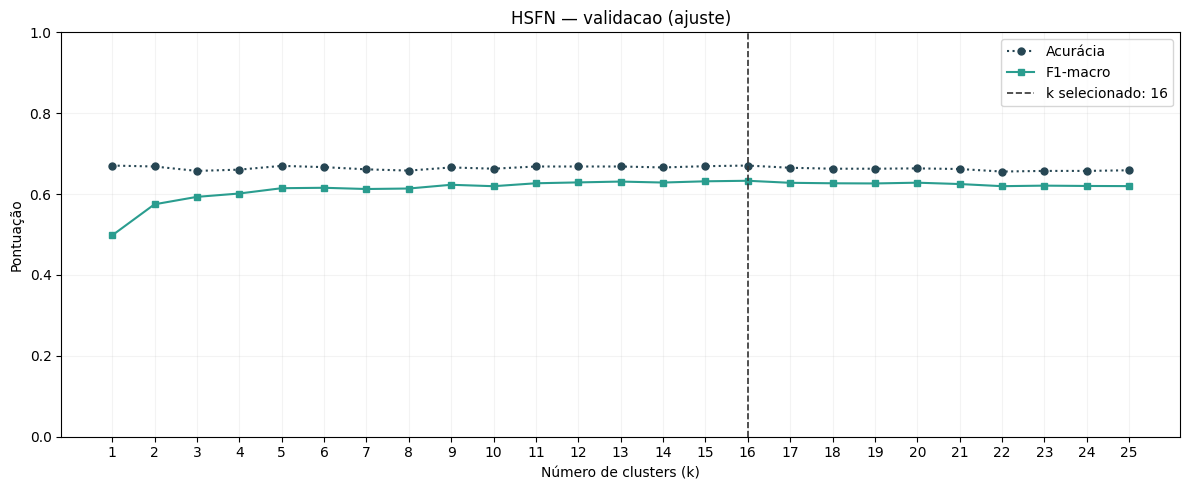

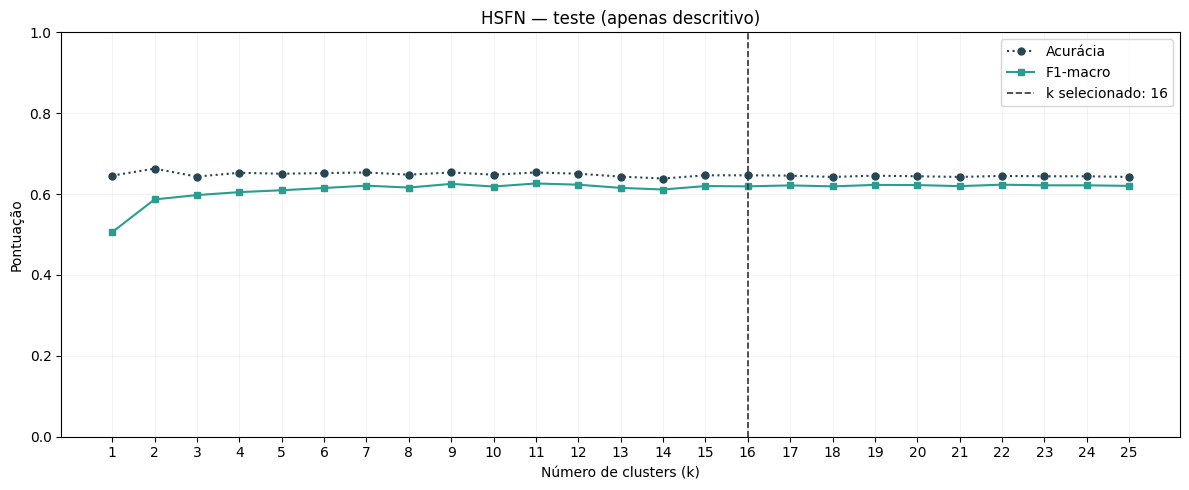

In [ ]:

# ============================================================
# HSFN — DESEMPENHO EM FUNÇÃO DE K
# ============================================================

ks = selection_results[
    selection_results.group.str.startswith('HSFN k=')
].copy()

kt = curves[
    curves.group.str.startswith('HSFN k=')
].copy()

K_HSFN_PRINCIPAL = int(BEST_D.split('=')[1])

for frame in (ks, kt):
    frame['k'] = frame.group.str.extract(r'k=(\d+)')[0].astype(int)
    frame.sort_values('k', inplace=True)

# Configurações visuais
METRIC_COLORS = ['#264653', '#2A9D8F']
METRIC_MARKERS = ['o', 's']
METRIC_STYLES = [':', '-']

for frame, split, metrics in [
    (ks, 'validacao', ['accuracy_validation', 'f1_validation']),
    (kt, 'teste', ['accuracy', 'f1_macro'])
]:

    fig, ax = plt.subplots(figsize=(12, 5))

    for metric, title, color, marker, style in zip(
        metrics,
        ['Acurácia', 'F1-macro'],
        METRIC_COLORS,
        METRIC_MARKERS,
        METRIC_STYLES
    ):

        ax.plot(
            frame.k,
            frame[metric],
            marker=marker,
            color=color,
            linestyle=style,
            linewidth=1.5,
            markersize=5,
            label=title
        )

    # K selecionado na validação
    ax.axvline(
        K_HSFN_PRINCIPAL,
        ls='--',
        color='#333333',
        linewidth=1.2,
        label=f'k selecionado: {K_HSFN_PRINCIPAL}'
    )

    ax.set(
        xlabel='Número de clusters (k)',
        xticks=range(1, len(MODEL_NAMES) + 1),
        ylabel='Pontuação',
        ylim=(0, 1),
        title=f'HSFN — {split}' + (
            ' (apenas descritivo)'
            if split == 'teste'
            else ' (ajuste)'
        )
    )

    ax.grid(alpha=0.15)

    # Legenda interna
    ax.legend(
        loc='best',
        frameon=True,
        facecolor='white',
        edgecolor='#CCCCCC',
        fontsize=10
    )

    fig.tight_layout()

    fig.savefig(
        OUT / f'hsfn_k_{split}_liar.jpg',
        dpi=300,
        bbox_inches='tight',
        facecolor='white'
    )

    plt.show()
    plt.close(fig)


In [ ]:
ds = 'liar'
k = 16

selected_models = REPRESENTATIVES[ds][k]

df_selected = pd.DataFrame({
    'Classificador': selected_models,
    'Representação': [embedding(m).upper() for m in selected_models],
    'Algoritmo': [algorithm(m) for m in selected_models],
    'F1-macro validação': [
        val_metrics[ds][m] for m in selected_models
    ]
})

print(f'HSFN — k={k}')
print(f'Total de classificadores: {len(selected_models)}')

display(
    df_selected.sort_values(
        'F1-macro validação',
        ascending=False
    ).reset_index(drop=True)
)

HSFN — k=16
Total de classificadores: 16


,Classificador,Representação,Algoritmo,F1-macro validação
0,CV-KNN,CV,KNN,0.589524
1,BERT-NB,BERT,NB,0.588940
2,W2V-NB,W2V,NB,0.588803
3,BERT-KNN,BERT,KNN,0.585905
4,FASTTEXT-NB,FASTTEXT,NB,0.583454
5,CV-NB,CV,NB,0.571650
6,W2V-KNN,W2V,KNN,0.567992
7,FASTTEXT-KNN,FASTTEXT,KNN,0.567395
8,TFIDF-KNN,TFIDF,KNN,0.562921
9,TFIDF-RF,TFIDF,RF,0.557130


In [ ]:
print(', '.join(REPRESENTATIVES['liar'][16]))

BERT-SVM, BERT-KNN, BERT-CNN, BERT-NB, BERT-RF, CV-KNN, CV-CNN, CV-NB, TFIDF-KNN, TFIDF-CNN, TFIDF-RF, W2V-SVM, W2V-KNN, W2V-NB, FASTTEXT-KNN, FASTTEXT-NB


## 7. Oracle — potencial de complementaridade
Referência hipotética com acesso ao rótulo verdadeiro. Não é um modelo treinável. Acurácia é o limite superior de um seletor que escolhe uma das predições disponíveis; F1-macro é descritivo. O teste não orienta seleção.

,split,group,n_models,accuracy,f1_macro,all_correct,all_wrong,partial_correct,gap_vs_best
0,validation,Todos,25,0.948598,0.938970,0.234424,0.051402,0.714174,0.279595
1,validation,CPS,6,0.887850,0.858090,0.362150,0.112150,0.525701,0.218847
2,validation,HSFN,16,0.944704,0.934103,0.239097,0.055296,0.705607,0.275701
3,test,Todos,25,0.939227,0.930631,0.195738,0.060773,0.743489,0.319653
4,test,CPS,6,0.882399,0.858797,0.322021,0.117601,0.560379,0.262826
5,test,HSFN,16,0.938437,0.929685,0.198106,0.061563,0.740331,0.318863


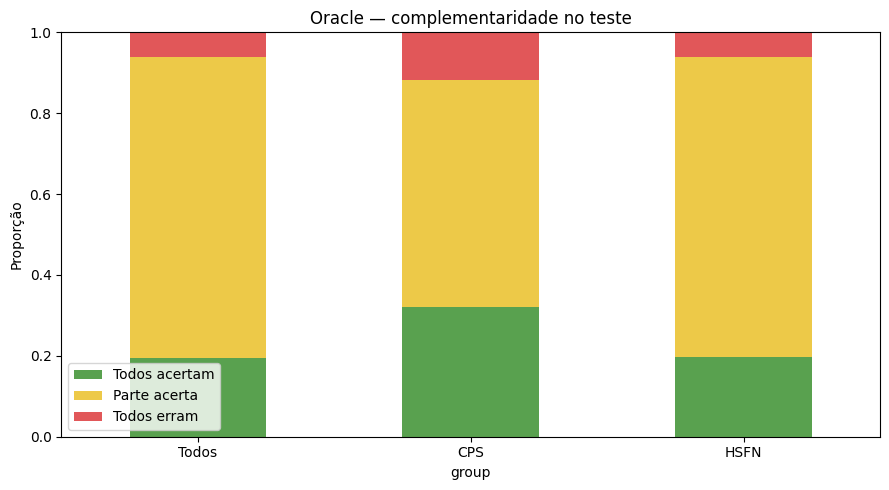

In [ ]:
# Oracle: seletor ideal que conhece o rótulo real; não é modelo implantável.
oracle_rows=[]; oracle_preds={}
for split in ('validation','test'):
    y=data['y'][split]
    for group, models in {'Todos':MODEL_NAMES,'CPS':GROUPS[ds]['CPS'],'HSFN':GROUPS[ds][BEST_D]}.items():
        correct=np.column_stack([data['pred'][split][m]==y for m in models])
        any_correct=correct.any(axis=1); all_correct=correct.all(axis=1)
        # Binário: se todos erram, todos predizem a classe oposta.
        p=np.where(any_correct,y,1-y)
        oracle_preds[(split,group)]=p
        acc_best=accuracy_score(y,data['pred'][split][best])
        oracle_rows.append(dict(split=split,group=group,n_models=len(models),accuracy=accuracy_score(y,p),f1_macro=f1_score(y,p,average='macro',zero_division=0),all_correct=all_correct.mean(),all_wrong=(~any_correct).mean(),partial_correct=(any_correct & ~all_correct).mean(),gap_vs_best=accuracy_score(y,p)-acc_best))
oracle_df=pd.DataFrame(oracle_rows)
display(oracle_df)
oracle_df.to_csv(OUT/'oracle.csv',index=False)
t=oracle_df.query('split == "test"').set_index('group')
ax=t[['all_correct','partial_correct','all_wrong']].rename(columns={'all_correct':'Todos acertam','partial_correct':'Parte acerta','all_wrong':'Todos erram'}).plot.bar(stacked=True,rot=0,figsize=(9,5),color=['#59A14F','#EDC948','#E15759'])
ax.set(ylabel='Proporção',ylim=(0,1),title='Oracle — complementaridade no teste'); ax.figure.tight_layout(); ax.figure.savefig(OUT/'oracle_complementaridade.jpg',dpi=300); plt.show()
# Comparação com Oracle de todo o pool; referência hipotética, não método treinado.
r=t.loc['Todos']; results=pd.concat([results,pd.DataFrame([dict(split='test',group='Oracle',accuracy=r.accuracy,f1_macro=r.f1_macro)])],ignore_index=True)


## 8. Comparação final — CPS, HSFN, Todos e melhor monolítico

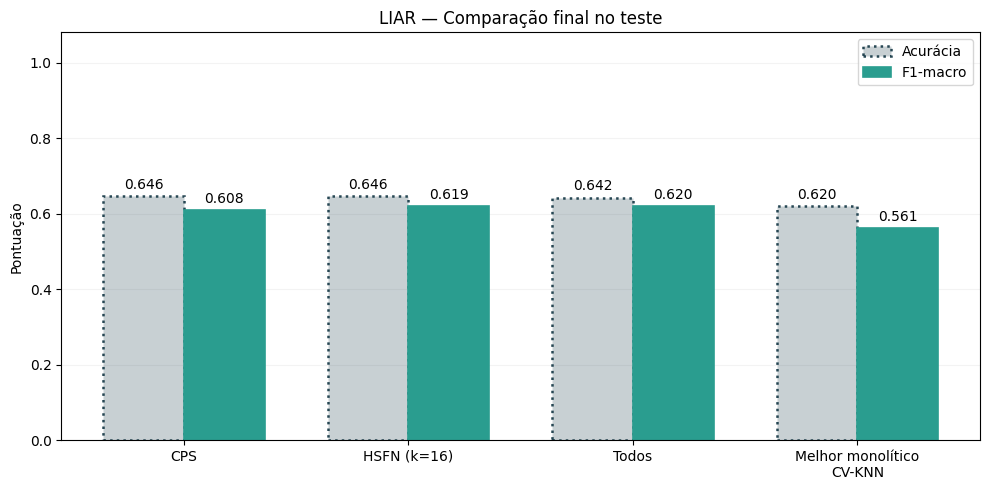

,group,split,accuracy,f1_macro
0,CPS,test,0.646409,0.608342
1,HSFN,test,0.646409,0.619144
2,Todos,test,0.642463,0.620316
3,Melhor monolítico | CV-KNN,test,0.619574,0.560942


In [ ]:

# ============================================================
# COMPARAÇÃO FINAL — LIAR
# ============================================================

sub = results.set_index('group').loc[
    ['CPS', 'HSFN', 'Todos', f'Melhor monolítico | {best}']
].reset_index()

x = np.arange(len(sub))
width = 0.36

fig, ax = plt.subplots(figsize=(10, 5))

# Acurácia — preenchimento suave e contorno pontilhado
bars_acc = ax.bar(
    x - width/2,
    sub['accuracy'],
    width,
    label='Acurácia',
    facecolor='#26465340',
    edgecolor='#264653',
    linestyle=':',
    linewidth=1.8
)

# F1-macro — preenchimento sólido
bars_f1 = ax.bar(
    x + width/2,
    sub['f1_macro'],
    width,
    label='F1-macro',
    facecolor='#2A9D8F',
    edgecolor='#2A9D8F',
    linestyle='-',
    linewidth=1.2
)

# Valores acima das barras
ax.bar_label(bars_acc, fmt='%.3f', padding=3, fontsize=10)
ax.bar_label(bars_f1, fmt='%.3f', padding=3, fontsize=10)

# Configuração dos eixos
ax.set(
    ylabel='Pontuação',
    ylim=(0, 1.08),
    title='LIAR — Comparação final no teste'
)

ax.set_xticks(
    x,
    [
        'CPS',
        f'HSFN (k={K_HSFN_PRINCIPAL})',
        'Todos',
        f'Melhor monolítico\n{best}'
    ]
)

# Grade ao fundo
ax.set_axisbelow(True)
ax.grid(axis='y', alpha=0.15)

# Legenda interna
ax.legend(
    loc='best',
    frameon=True,
    facecolor='white',
    edgecolor='#CCCCCC',
    fontsize=10
)

fig.tight_layout()

fig.savefig(
    OUT / 'comparacao_principal_liar.jpg',
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()
plt.close(fig)

display(sub)



## 9. Exportação dos resultados

In [ ]:
for name,frame in [('comparacao',results),('curvas_teste',curves),('selecao_validacao',selection_results),('clusters',clusters_df),('representantes',representatives_df)]:
    frame.to_csv(OUT/f'{name}.csv',index=False)
pd.DataFrame(DOUBLE_FAULT[ds],index=MODEL_NAMES,columns=MODEL_NAMES).to_csv(OUT/'double_fault.csv')
pd.DataFrame(DISTANCES[ds],index=MODEL_NAMES,columns=MODEL_NAMES).to_csv(OUT/'discordancia_erros.csv')
pd.DataFrame(CPS_DISTANCES[ds],index=MODEL_NAMES,columns=MODEL_NAMES).to_csv(OUT/'cps_dissimilarity.csv')
pd.DataFrame(CPS_COORDS[ds],index=MODEL_NAMES,columns=['CPS1','CPS2']).to_csv(OUT/'cps.csv')
(OUT/'protocolo.json').write_text(json.dumps(dict(seed=SEED,use_sample=USE_SAMPLE,sample_size=SAMPLE_SIZE,split_sizes={s:len(df) for s,df in labels.items()},cps=CPS_SELECTIONS,hsfn=BEST_D,monolitico=best,validation='inteira; ajuste e seleção'),indent=2))
import shutil
archive=shutil.make_archive(str(ROOT/'resultados_liar_25_binario_umap'),'zip',root_dir=ROOT/'liar_25_binario_umap_results')
print(archive)

/content/resultados_liar_50_binario_umap.zip
